In [1]:
import pathlib
import numpy as np
import scipy as sp
from astropy.io import fits
import matplotlib.pyplot as plt
from scipy import ndimage

In [2]:
here = pathlib.Path('.')
calibration_image = "ubai2505m"
calib_dir = here / "hst-data" / "calibration"

In [3]:
def load_calibration_image(image_id, folder=here):
    """Return {file_type: {'data': array, 'header': primary header}} for one image id.

    Handles the three layouts in the data: a 3D image in the primary HDU, a 3D image
    in an extension, or one 2D image extension per chip (stacked into 3D).
    """
    cal = {}
    for file in sorted(folder.rglob(image_id + "_*.fits")):
        file_type = file.stem.split("_", 1)[1]   # 'ubai2505m_maskfile' -> 'maskfile'
        with fits.open(file) as hdul:
            images = [h.data for h in hdul
                      if isinstance(h, (fits.PrimaryHDU, fits.ImageHDU)) and h.data is not None]
            if not images:
                raise ValueError(f"No image data found in {file}")
            data = images[0] if len(images) == 1 else np.stack(images)
            cal[file_type] = {'data': data.copy(), 'header': hdul[0].header.copy()}
    return cal

In [4]:
cal = load_calibration_image(calibration_image, calib_dir)

for file_type, entry in cal.items():
    print(file_type, entry['data'].shape, entry['data'].dtype)

atodfile (4, 2, 4096) >f4
biasfile (4, 800, 800) >f4
blevfile (4, 800, 14) int16
darkfile (4, 800, 800) >f4
flatfile (4, 800, 800) >f4
maskfile (4, 800, 800) >i2
raw (4, 800, 800) >i2


1HISTORY   below the initial guess image. The first initial guess image          [astropy.io.fits.card]


In [5]:
def apply_mask(cal, defective=2, questionable=256, reject_questionable=False):
    """Mask the raw image with the MASKFILE.

    Defective pixels become NaN. Questionable pixels keep their values unless
    reject_questionable=True, and are returned as a boolean array either way.

    Returns (masked_data, questionable_pixels).
    """
    raw = cal['raw']['data']
    mask = cal['maskfile']['data']

    if raw.shape != mask.shape:
        raise ValueError(f"Raw shape {raw.shape} does not match mask shape {mask.shape}")

    unexpected = set(np.unique(mask)) - {0, defective, questionable}
    if unexpected:
        raise ValueError(f"Mask contains unexpected values: {sorted(unexpected)}")

    data = raw.astype(np.float64)   # new array: the raw data stays untouched, and floats can hold NaN

    bad = mask == defective
    is_questionable = mask == questionable
    if reject_questionable:
        bad = bad | is_questionable

    data[bad] = np.nan
    return data, is_questionable


def save_fits(data, header, path, history=None):
    """Save data with a copy of the header, adding a HISTORY line describing the step."""
    path = pathlib.Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    header = header.copy()
    if history:
        header['HISTORY'] = history
    fits.writeto(path, data, header, overwrite=True)

In [6]:
masked, questionable = apply_mask(cal)

# Check: every defective pixel should now be NaN, and nothing else
print("defective in mask:", np.sum(cal['maskfile']['data'] == 2))
print("NaN in result:    ", np.sum(np.isnan(masked)))
print("questionable kept:", np.sum(questionable))

defective in mask: 5430
NaN in result:     5430
questionable kept: 13378


In [7]:
save_fits(masked, cal['raw']['header'],
          here / "hst-processed" / f"{calibration_image}_masked.fits",
          history="MASKFILE applied: defective (2) set to NaN, questionable (256) kept")

In [8]:
def subtract_bias_level(data, blev, rows=slice(9, 790), cols=slice(8, 14)):
    """Subtract the bias level measured in the BLEVFILE overscan, separately for even and odd columns.

    data : (chips, rows, cols) float image, e.g. the masked raw data
    blev : (chips, rows, 14) overscan from the BLEVFILE
    rows, cols : overscan region to average (guidance: FITS rows 10-790, columns 9-14)

    Parity uses Python indices throughout: the mean of the Python-even overscan columns is
    subtracted from the Python-even image columns, and likewise for odd. Since FITS numbering
    is Python + 1, this is the same pairing in FITS terms, so no conversion is needed.

    Returns (corrected_data, levels) where levels[chip] = [even_level, odd_level].
    """
    overscan = blev[:, rows, cols].astype(np.float64)
    corrected = data.astype(np.float64)   # new array, so the input stays untouched
    levels = np.empty((data.shape[0], 2))

    for chip in range(data.shape[0]):
        for parity in (0, 1):
            # Position within the overscan slice of the first column with this Python parity
            start = (parity - cols.start) % 2
            level = overscan[chip][:, start::2].mean()
            corrected[chip, :, parity::2] -= level
            levels[chip, parity] = level

    return corrected, levels

In [9]:
bias_corrected, bias_levels = subtract_bias_level(masked, cal['blevfile']['data'])

for chip, (even, odd) in enumerate(bias_levels):
    print(f"chip {chip} (DETECTOR {chip + 1}): even {even:.4f}, odd {odd:.4f}")

# Compare chip 0 with the pipeline's values for DETECTOR 1
c0m_hdr = fits.getheader(here / "hst-data" / "F336W" / f"{calibration_image}_c0m_aligned.fits", 1)
print("pipeline: BIASEVEN", c0m_hdr['BIASEVEN'], " BIASODD", c0m_hdr['BIASODD'])

# NaN pixels should stay NaN, and no new ones should appear
print("NaN before:", np.sum(np.isnan(masked)), " after:", np.sum(np.isnan(bias_corrected)))

save_fits(bias_corrected, cal['raw']['header'],
          here / "hst-processed" / f"{calibration_image}_blev.fits",
          history="BLEVFILE applied: mean overscan bias level subtracted per chip, even/odd columns")

chip 0 (DETECTOR 1): even 299.5847, odd 299.5915
chip 1 (DETECTOR 2): even 319.9603, odd 319.9334
chip 2 (DETECTOR 3): even 313.4831, odd 313.4648
chip 3 (DETECTOR 4): even 298.7443, odd 298.7499
pipeline: BIASEVEN 299.5152  BIASODD 299.5215
NaN before: 5430  after: 5430


In [10]:
def subtract_bias_image(data, bias):
    """Step 4: subtract the BIASFILE, the residual bias pattern left after the bias level."""
    return data - bias


def subtract_dark(data, dark, dark_time, dark_ref_time=1.0):
    """Step 5: subtract the DARKFILE scaled to this exposure's dark time.

    The DARKFILE header has DARKTIME = 1, so it is a dark rate per second; scale it
    by the raw image's DARKTIME (the time the chip collected dark current).
    """
    return data - dark * (dark_time / dark_ref_time)


def apply_flat(data, flat, inverse=True):
    """Step 6: flat-field correction.

    WFPC2 FLATFILEs are inverse flats, so they are multiplied. Multiplying matches the
    pipeline image far better than dividing; set inverse=False to divide as in the guidance formula.
    """
    return data * flat if inverse else data / flat


def photometric_calibration(data, exptime, photflam):
    """Step 8: convert counts to flux density (erg / s / cm^2 / Angstrom) using PHOTFLAM."""
    return data / exptime * photflam


def flux_to_mag(flux, photzpt, zp_corr=0.0):
    """Step 8: convert flux density to STMAG magnitudes; ZP_CORR corrects for contamination."""
    return -2.5 * np.log10(flux) + photzpt + zp_corr

In [11]:
raw_hdr = cal['raw']['header']

debiased = subtract_bias_image(bias_corrected, cal['biasfile']['data'])
dark_subtracted = subtract_dark(debiased, cal['darkfile']['data'],
                                dark_time=raw_hdr['DARKTIME'],
                                dark_ref_time=cal['darkfile']['header']['DARKTIME'])
calibrated = apply_flat(dark_subtracted, cal['flatfile']['data'])

save_fits(calibrated, raw_hdr,
          here / "hst-processed" / f"{calibration_image}_calibrated.fits",
          history="BIASFILE subtracted, DARKFILE scaled by DARKTIME subtracted, FLATFILE (inverse flat) multiplied")

# The pipeline image is DETECTOR 1 (chip 0) and holds the photometry keywords for that chip
pipeline_path = here / "hst-data" / "F336W" / f"{calibration_image}_c0m_aligned.fits"
pipeline = fits.getdata(pipeline_path, 1)
pipeline_hdr = fits.getheader(pipeline_path, 1)

flux = photometric_calibration(calibrated[0], raw_hdr['EXPTIME'], pipeline_hdr['PHOTFLAM'])

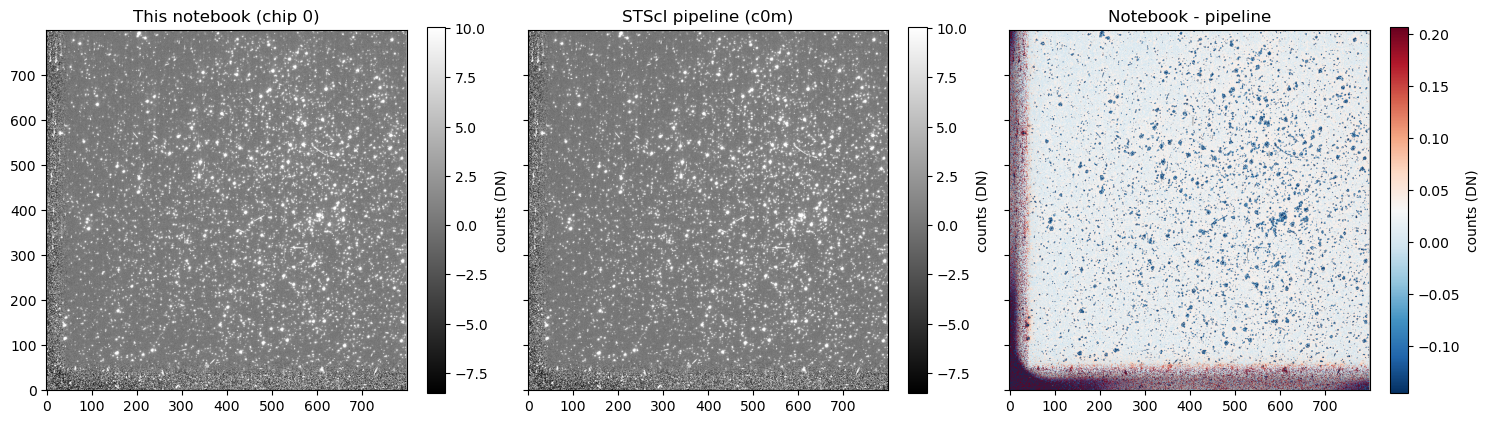

In [12]:
from astropy.visualization import ImageNormalize, ZScaleInterval

# Same display scaling for both images, so differences are real and not a contrast effect
norm = ImageNormalize(pipeline, interval=ZScaleInterval())
difference = calibrated[0] - pipeline

fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharex=True, sharey=True)
panels = [(calibrated[0], 'This notebook (chip 0)', norm, 'gray'),
          (pipeline, 'STScI pipeline (c0m)', norm, 'gray'),
          (difference, 'Notebook - pipeline', ImageNormalize(difference, interval=ZScaleInterval()), 'RdBu_r')]

for ax, (image, title, image_norm, cmap) in zip(axes, panels):
    im = ax.imshow(image, origin='lower', cmap=cmap, norm=image_norm)
    ax.set_title(title)
    fig.colorbar(im, ax=ax, fraction=0.046, label='counts (DN)')

plt.tight_layout()
plt.show()